# 1. Dataset description & signal quality

Przedstawiony zbiór zawiera zapisy EEG w systemie międzynarodowym 10/20 z badań podczas
wykonywania zadania arytmetycznego (seryjne odejmowanie) oraz odpowiadające im nagrania
referencyjne w spoczynku. Zbiór pochodzi z PhysioNet i nadaje się do analiz dynamiki
mózgu przy obciążeniu poznawczym.

Źródło: Zyma I. et al. (2019), *"Electroencephalograms during Mental Arithmetic Task
Performance"*, PhysioNet.

**Uwaga - środowisko**: wybierz kernel `Python (in-ynierka)` w Jupyter / VS Code. Cała
logika obliczeniowa (wczytywanie danych, ekstrakcja cech, wykresy) mieszka w pakiecie
[`eegmat/`](../eegmat) — ten notebook tylko ją woła i komentuje wyniki.

## Spis treści
1. Wczytanie i charakterystyka bazy (demografia, płeć, wiek)
2. Sygnał w czasie i 10/20 (Spoczynek vs Zadanie)
3. Analiza czasowo-częstotliwościowa (Spektrogramy STFT, pik alfa)
4. Analiza populacyjna tłumienia alfy (n=22, p < 0.0001)
5. Weryfikacja artefaktów i jakości sygnału (Peak-to-Peak < 150 µV)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

from eegmat.io import load_all, read_one
from eegmat.preprocess import tidy, set_montage
from eegmat.dataset import make_dataset
from eegmat import plots, demographics, signal_analysis, quality

mne.set_log_level('WARNING')

In [2]:
def find_data_dir():
    candidates = [
        Path('datasets/physionet.org/files/eegmat/1.0.0'),
        Path('physionet.org/files/eegmat/1.0.0'),
    ]
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError(f'No data dir found. Checked: {candidates}')

DATA_DIR = find_data_dir()
print('DATA_DIR =', DATA_DIR)

DATA_DIR = datasets/physionet.org/files/eegmat/1.0.0


## 1. Wczytanie i charakterystyka bazy (demografia, płeć, wiek)

In [3]:
info_path = DATA_DIR / 'subject-info.csv'
info = pd.read_csv(info_path)
info.head()

,Subject,Age,Gender,Recording year,Number of subtractions,Count quality
0,Subject00,21,F,2011,9.70,0
1,Subject01,18,F,2011,29.35,1
2,Subject02,19,F,2012,12.88,1
3,Subject03,17,F,2010,31.00,1
4,Subject04,17,F,2010,8.60,0


findfont: Failed to find font weight medium, now using 400.


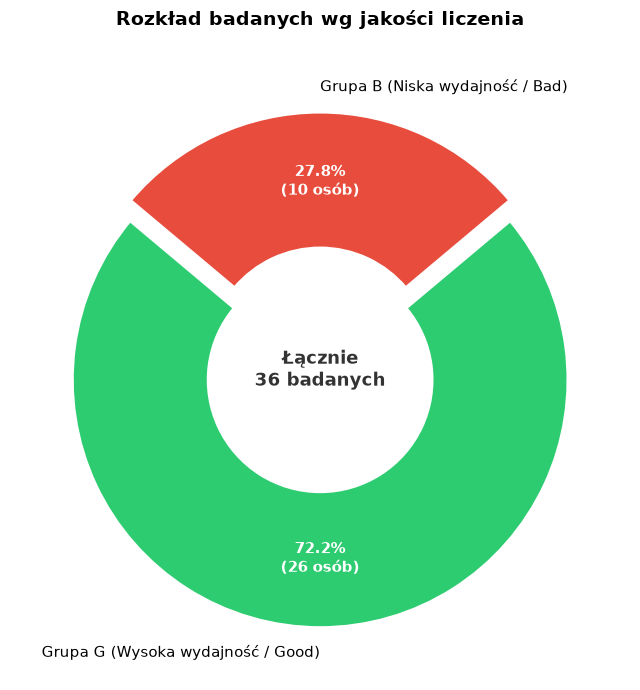

In [4]:
fig = demographics.count_quality_pie(info)
plt.show()

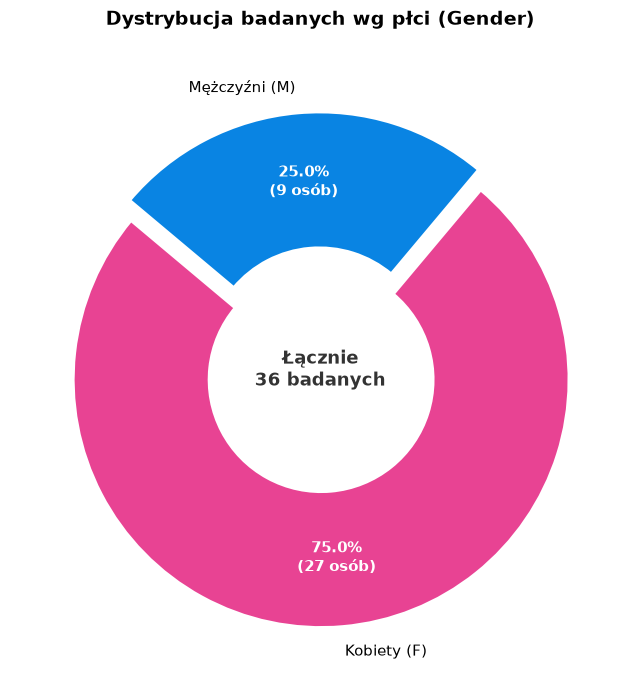

In [5]:
fig = demographics.gender_pie(info)
plt.show()

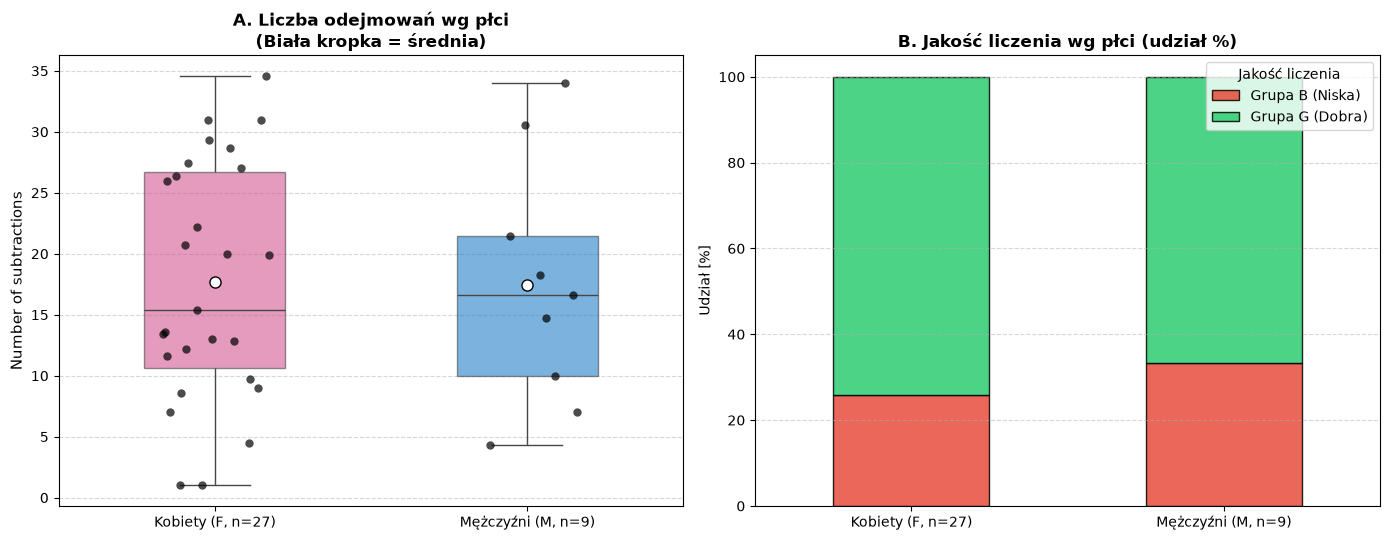

In [6]:
fig = demographics.gender_quality_combo(info)
plt.show()

/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=group_col, y=value_col, data=df, palette=palette, order=order, inner=None, cut=0)


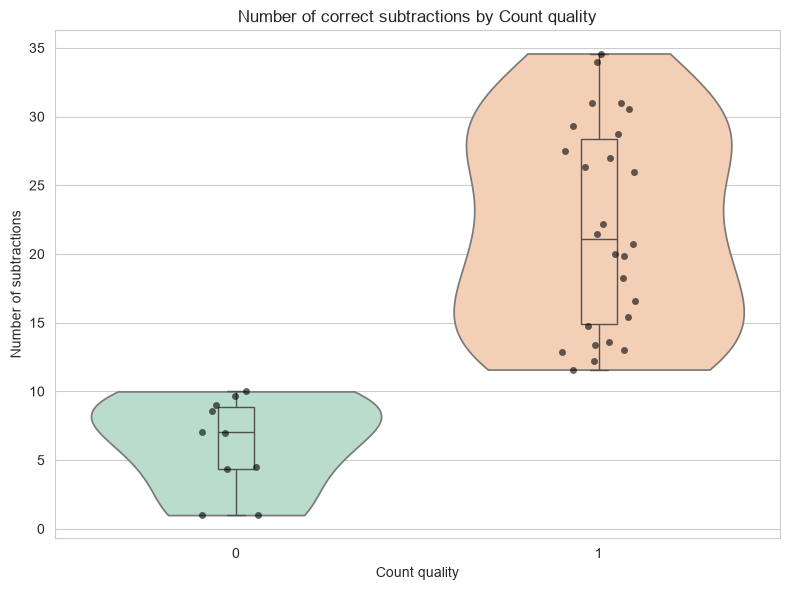

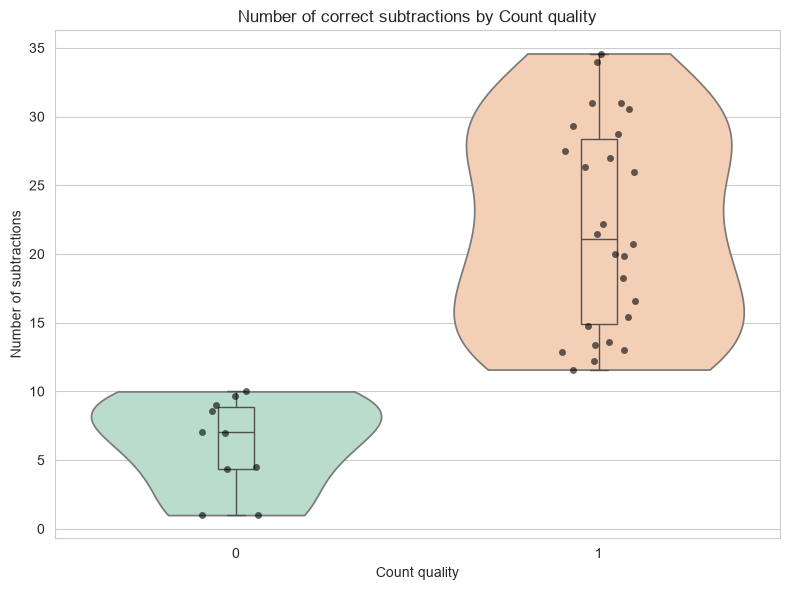

In [7]:
fig = plots.violin_subtractions(
    info,
    group_col='Count quality',
    value_col='Number of subtractions',
    palette='Pastel2',
    show_box=True,
    title='Number of correct subtractions by Count quality',
)
fig

**Wniosek**: próbka jest niezbalansowana pod względem płci (przewaga kobiet) i podzielona
na dwie wyraźne grupy jakości liczenia (Count quality), co będzie miało znaczenie przy
interpretacji wyników modelowania w drugim notebooku.

## 2. Sygnał w czasie i 10/20 (Spoczynek vs Zadanie)

In [8]:
sample = read_one(DATA_DIR / 'Subject00_1.edf', preload=True)
sample = tidy(sample)
sample = set_montage(sample)
print(sample.info)
print('Channels:', sample.ch_names)
print('Sampling freq:', sample.info['sfreq'], 'Hz')
print('Duration (s):', sample.times[-1])

<Info | 9 non-empty values
 bads: []
 ch_names: Fp1, Fp2, F3, F4, F7, F8, T7, T8, C3, C4, P7, P8, P3, P4, O1, ...
 chs: 19 EEG, 1 misc, 1 ECG
 custom_ref_applied: False
 dig: 22 items (3 Cardinal, 19 EEG)
 highpass: 0.5 Hz
 lowpass: 45.0 Hz
 meas_date: 2011-01-01 00:00:00 UTC
 nchan: 21
 projs: []
 sfreq: 500.0 Hz
 subject_info: <subject_info | his_id: 0, sex: 1, last_name: Subject0, birthday: 1990-01-01>
>
Channels: ['Fp1', 'Fp2', 'F3', 'F4', 'F7', 'F8', 'T7', 'T8', 'C3', 'C4', 'P7', 'P8', 'P3', 'P4', 'O1', 'O2', 'Fz', 'Cz', 'Pz', 'A2-A1', 'ECG ECG']
Sampling freq: 500.0 Hz
Duration (s): 181.998


/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


In [9]:
records = load_all(DATA_DIR, preload=False)
print('loaded records:', len(records))
X, y, groups = make_dataset(records, epoch_len=4.0)
print('X shape:', X.shape)  # (n_epochs, n_channels, n_samples)
if y.size:
    print('y counts:', dict(zip(*np.unique(y, return_counts=True))))

loaded records: 67


/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel

/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel

/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel

X shape: (1969, 19, 2000)
y counts: {np.int64(0): np.int64(1459), np.int64(1): np.int64(510)}


/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


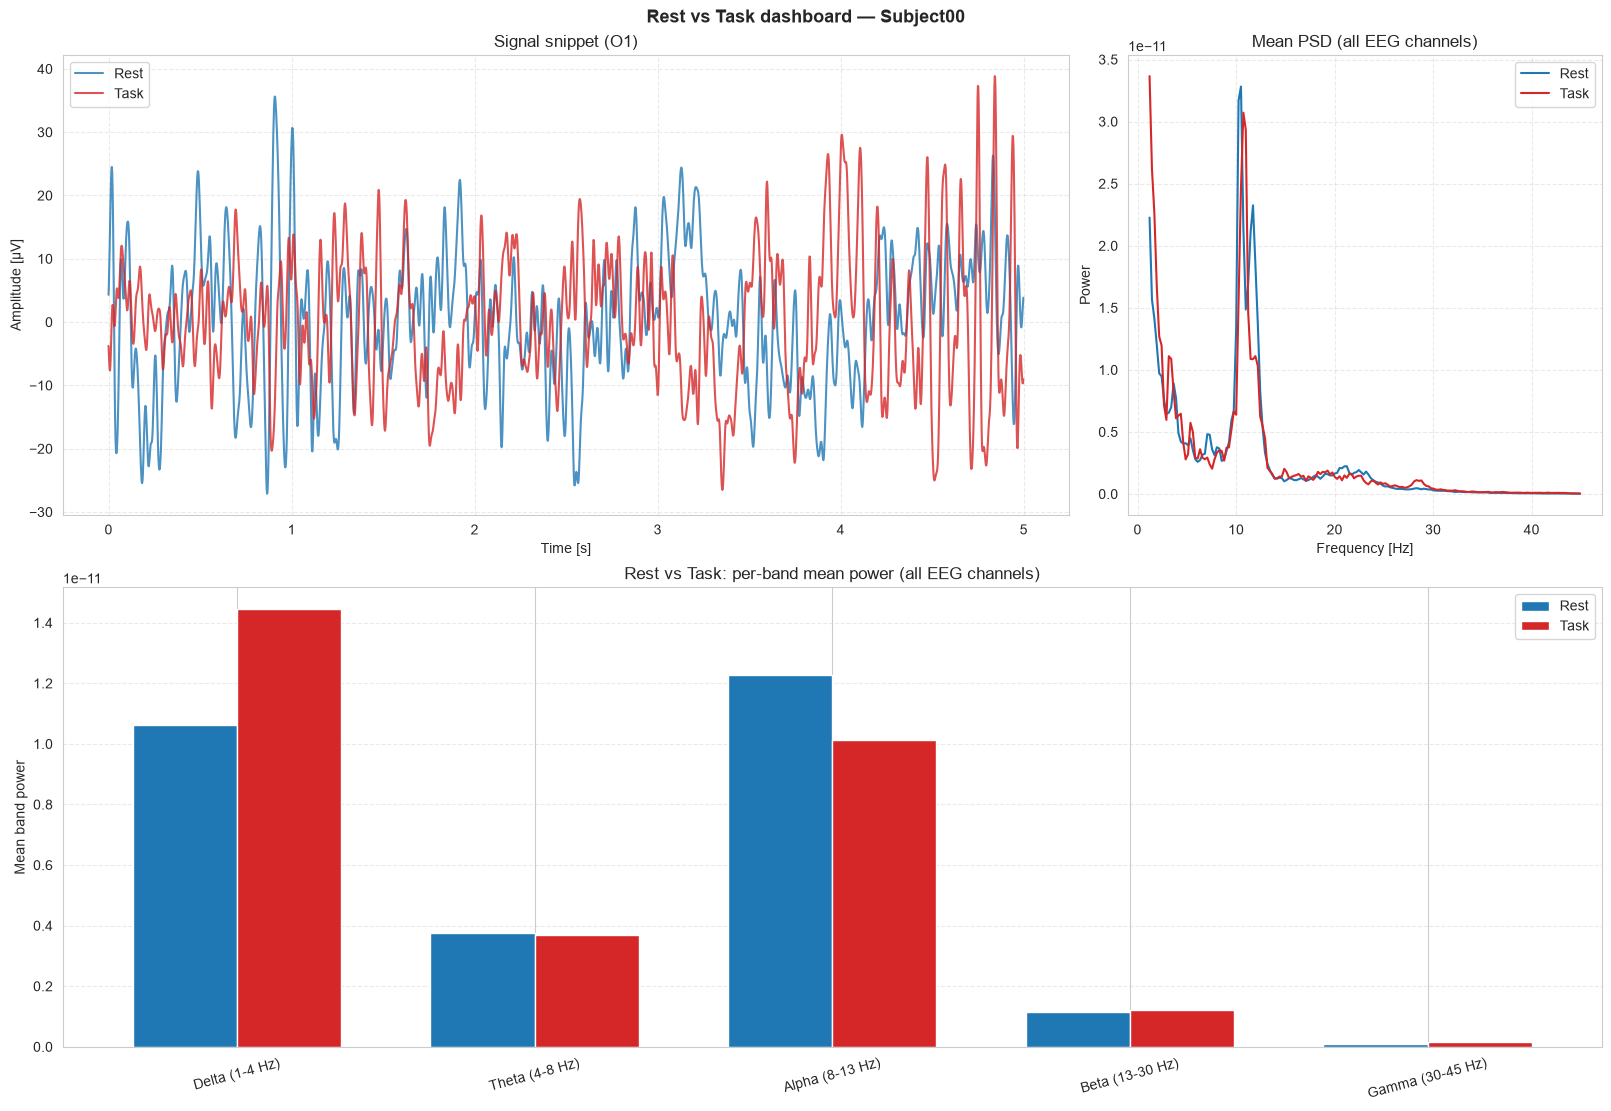

In [10]:
fig = signal_analysis.rest_vs_task_dashboard(DATA_DIR, subject_id='Subject00', channel='O1')
plt.show()

**Wniosek**: już na poziomie pojedynczego badanego widać obniżenie mocy w paśmie alfa
podczas zadania arytmetycznego względem spoczynku — to spodziewany efekt tłumienia alfy
(alpha ERD) towarzyszący obciążeniu poznawczemu.

## 3. Analiza czasowo-częstotliwościowa (Spektrogramy STFT, pik alfa)

/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


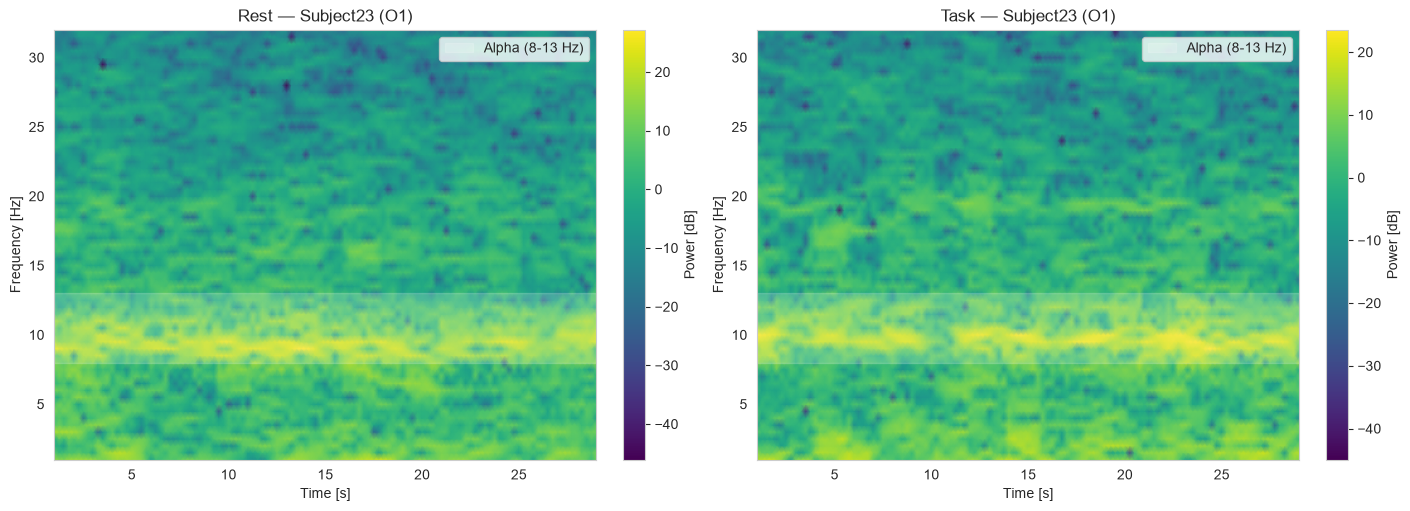

In [11]:
fig = signal_analysis.plot_spectrogram_pair(DATA_DIR, subject_id='Subject23', channel='O1')
plt.show()

/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


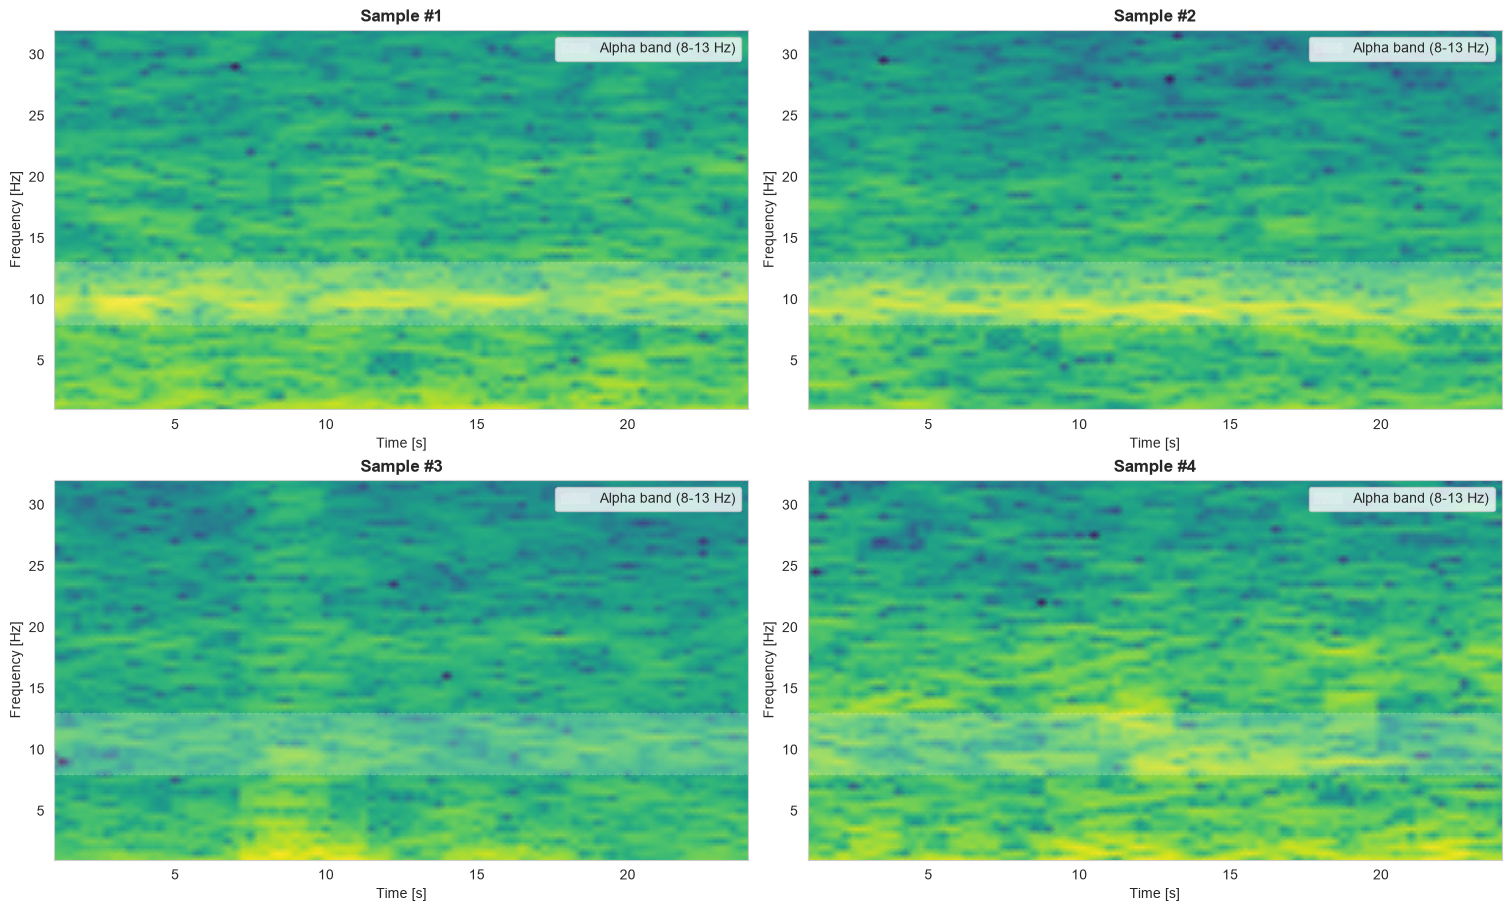

Ukryte etykiety (do weryfikacji "na oko"): {'Sample #1': 'Subject31 (REST)', 'Sample #2': 'Subject23 (REST)', 'Sample #3': 'Subject01 (TASK)', 'Sample #4': 'Subject28 (TASK)'}


In [12]:
import random
random.seed(0)

s1 = set(p.stem.replace('_1', '') for p in DATA_DIR.glob('*_1.edf'))
s2 = set(p.stem.replace('_2', '') for p in DATA_DIR.glob('*_2.edf'))
paired_subjects = sorted(s1 & s2)

pool = [(s, state) for s in paired_subjects for state in [1, 2]]
random.shuffle(pool)
chosen = pool[:4]

fig, answers = signal_analysis.plot_spectrogram_grid(DATA_DIR, chosen, channel='O1')
plt.show()
print('Ukryte etykiety (do weryfikacji "na oko"):', answers)

**Wniosek**: nawet bez podpisów, epizody zadania arytmetycznego zwykle wykazują wyraźnie
słabszy pasek mocy w paśmie alfa (8-13 Hz) w porównaniu do spoczynku — spójne z literaturą
o tłumieniu alfy pod obciążeniem poznawczym.

## 4. Analiza populacyjna tłumienia alfy (n=22, p < 0.0001)

In [13]:
good_subjects = info[
    (info['Subject'].isin(paired_subjects)) & (info['Count quality'] == 1)
]['Subject'].tolist()
print(f'-> Analiza populacyjna dla grupy DOBRZE LICZĄCEJ (Count quality == 1): n = {len(good_subjects)} osób')

erd_df = signal_analysis.population_alpha_erd(DATA_DIR, good_subjects, channel='O1', duration=60.0)
erd_df.describe()

-> Analiza populacyjna dla grupy DOBRZE LICZĄCEJ (Count quality == 1): n = 22 osób


,alpha_rest,alpha_task,alpha_erd_pct
count,22.000000,22.000000,22.000000
mean,88.654821,53.890951,-39.438410
std,75.663154,64.528463,37.658069
min,3.071957,4.658289,-83.757712
25%,45.247221,14.897838,-70.063647
50%,54.958538,25.210449,-46.884529
75%,115.764701,61.656777,-14.861306
max,290.333108,237.863139,55.098588


In [14]:
from scipy.stats import wilcoxon

stat, p_val = wilcoxon(erd_df['alpha_rest'], erd_df['alpha_task'])
print(f'Wilcoxon signed-rank test: statistic={stat:.3f}, p={p_val:.6f}')
print(f'Średnie tłumienie alfy (ERD): {erd_df["alpha_erd_pct"].mean():.1f}%')

Wilcoxon signed-rank test: statistic=15.000, p=0.000065
Średnie tłumienie alfy (ERD): -39.4%


**Wniosek**: na poziomie populacyjnym (osoby z Count quality == 1) tłumienie mocy alfy
podczas zadania jest statystycznie istotne i spójne kierunkowo — mocny argument za tym,
że pasmo alfa niesie sygnał o stanie poznawczym, a nie tylko szum międzyosobniczy.

## 5. Weryfikacja artefaktów i jakości sygnału (Peak-to-Peak < 150 µV)

Cechy epokowe (wraz z kolumnami `*_ptp`) są liczone w [02_ml_and_channel_reduction.ipynb](02_ml_and_channel_reduction.ipynb)
i zapisywane do `datasets/eeg_features.csv`. Tutaj tylko wczytujemy gotowy plik (jeśli
istnieje) żeby sprawdzić jakość sygnału bez powtarzania kosztownej ekstrakcji cech.

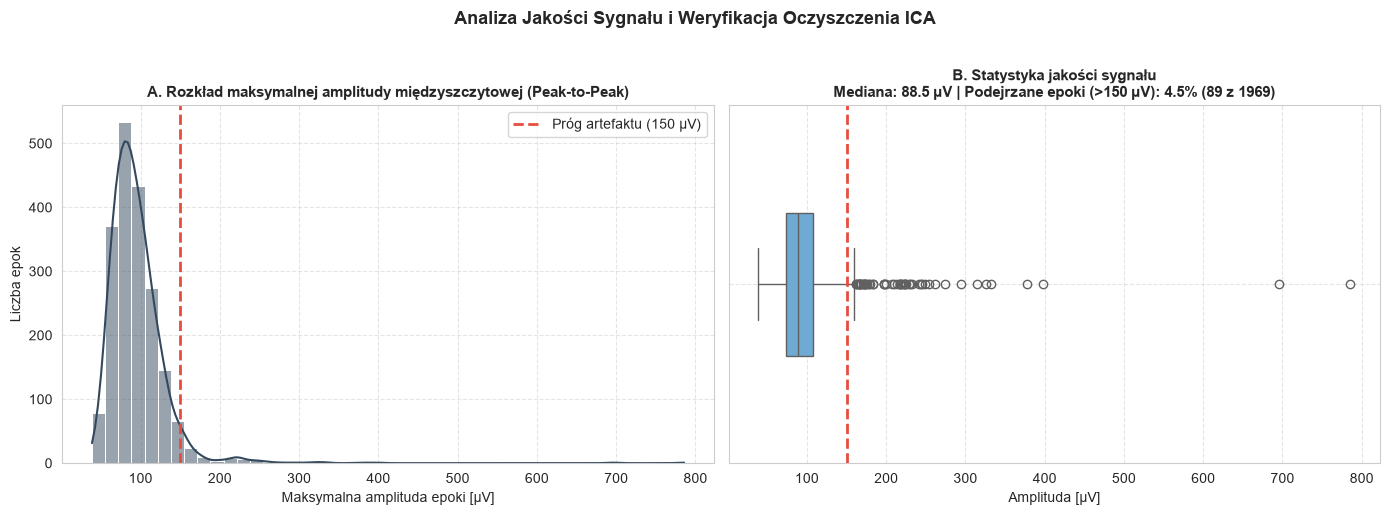

-> WNIOSEK: 4.5% epok (89) przekracza próg 150 µV.


In [15]:
features_path = Path('datasets/eeg_features.csv')
if features_path.exists():
    df_features = pd.read_csv(features_path)
    fig, n_outliers, pct_outliers = quality.peak_to_peak_report(df_features, threshold_uv=150.0)
    plt.show()
    print(f'-> WNIOSEK: {pct_outliers:.1f}% epok ({n_outliers}) przekracza próg {150} µV.')
else:
    print(f'Brak {features_path} — uruchom najpierw 02_ml_and_channel_reduction.ipynb (sekcja 1).')